In [ ]:
# Notes for 17 November 2026 class

print('test')

# Article that discussed resampling, fit_resample
#https://machinelearningmastery.com/random-oversampling-and-undersampling-for-imbalanced-classification/

test


In [2]:
import pandas as pd

diabetes_df = pd.read_csv("diabetes.csv")
diabetes_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# to understand if your dataset is imbalanced, look at value counts

diabetes_df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


# Logistic regression is for binary outcomes, 0 or 1, because linear regression won't
# work bc there is no line of best fit.

X = diabetes_df.drop(columns='Outcome')
y = diabetes_df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=10,
                                                    stratify=y)

In [4]:
%pip install imblearn



   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ---------------------------------------- 3/3 [imblearn]

Note: you may need to restart the kernel to use updated packages.


In [16]:
# resample our training data with RandomOverSampler (naive approach)
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=10)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

In [15]:
model = LogisticRegression(random_state=10)

# remember, for healthcare, recall is important for testing. false negatives are BAD
# when you're telling people if they have a disease or not.

In [14]:
from imblearn.under_sampling import ClusterCentroids

cc = ClusterCentroids(random_state=10)
X_train_resampled, y_train_resampled = cc.fit_resample(X_train, y_train)

c:\Users\phoen\anaconda3\envs\data-science-env\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [17]:
# ======================
# unsupervised learning
import numpy as np
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt

crime_df = pd.read_csv("USArrests.csv")
crime_df.head()

,State,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0
3,Arkansas,8.8,190,50,19.5
4,California,9.0,276,91,40.6


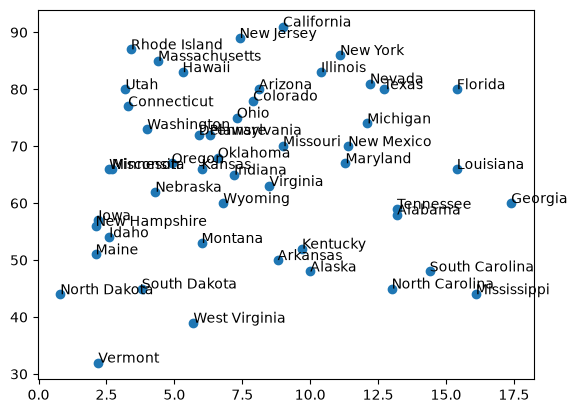

In [18]:
from sklearn.cluster import KMeans

X = crime_df.drop("State", axis=1)
y = crime_df["State"]

plt.scatter(X["Murder"], X["UrbanPop"])

# enumerating allows us to keep track of
# the indexes associated with each iteration

for i, txt in enumerate(y):
    plt.annotate(txt, (X["Murder"][i], X["UrbanPop"][i]))

In [19]:
inertias = []
distortions = []

for k in range(1,11):
    # build and fit the model
    model = KMeans(n_clusters=k, random_state=10).fit(X)

    # distortion is the average of the squared
    # distance from each point to its cluster's center
    # caveat: for our purposes, we'll be using Euclidian space

    # euclidian space is standard 2+ dimensional space that
    # we can imagine with our brains
    distance = cdist(X, model.cluster_centers_, 'euclidian')
    # shape in np tells us how big an object is, how many
    # indices it has
    distortion = sum(np.min(distance, axis=1))/X.shape[0]
    distortions.append(distortion)

    # inertia is calculated by measuring distance btwn
    # each data point and its assigned cluster's center,
    # then summing distances for all points.
    # A good model is one with LOW inertia or distortion
    # AND a low number of clusters, so as to avoid overfitting.
    inertia = model.inertia_
    inertias.append(inertia)

plt.plot(range(1,11), distortions, markers='o')


c:\Users\phoen\anaconda3\envs\data-science-env\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


ValueError: Unknown Distance Metric: euclidian

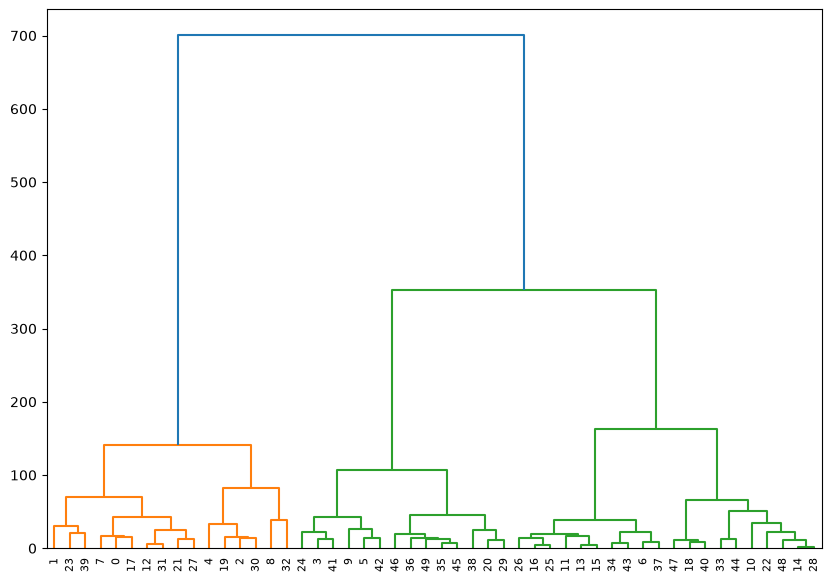

In [20]:
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(X, "ward")
plt.figure(figsize=(10,7))

dendogram = dendrogram(linked)

In [21]:
from sklearn.cluster import AgglomerativeClustering

# divides population into several clusters such that the data
# pts are in the same cluster as other data points similar
# to them.
# those in different clusters are NOT similar.

cluster = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels = cluster.fit_predict(X)
cluster.fit_predict(X)

array([1, 1, 1, 2, 1, 2, 0, 1, 1, 2, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 2, 1,
       0, 1, 2, 0, 0, 1, 0, 2, 1, 1, 1, 0, 0, 2, 2, 0, 2, 1, 0, 2, 2, 0,
       0, 2, 2, 0, 0, 2])

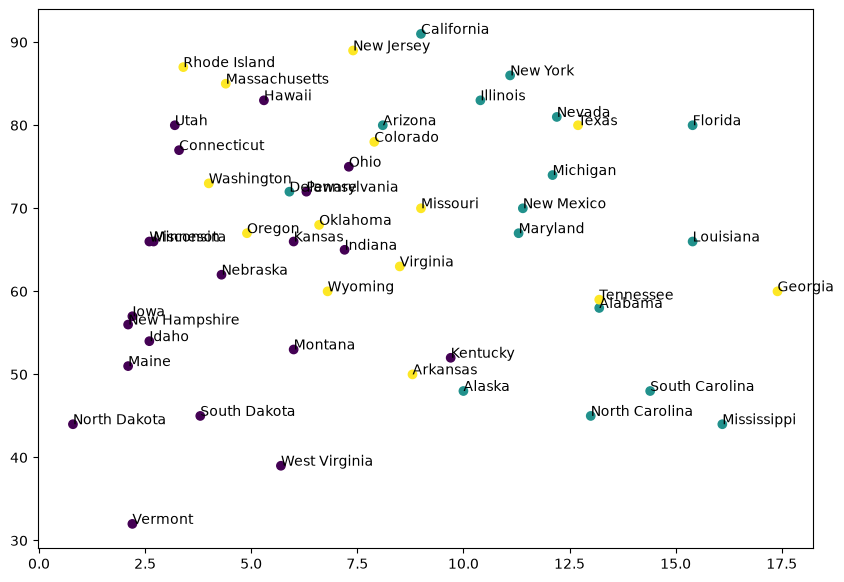

In [23]:
plt.figure(figsize=(10,7))
plt.scatter(X["Murder"], X["UrbanPop"], c=labels)
for i, txt in enumerate(y):
    plt.annotate(txt, (X["Murder"][i], X["UrbanPop"][i]))



In [24]:
# DIMENSIONALITY REDUCTION

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

diabetes_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [26]:
X = diabetes_df.drop("Outcome", axis=1)
y = diabetes_df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10)

model = LogisticRegression(random_state=10).fit(X_train, y_train)

# predicted outcome
y_predicted = model.predict(X_test)

from sklearn.metrics import recall_score
recall = recall_score(y_test, y_predicted.round())
recall

c:\Users\phoen\anaconda3\envs\data-science-env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.5084745762711864

In [ ]:
from sklearn.decomposition import TruncatedSVD
# singular value decomosotion = factorizatin technique
# for real or complex numbers in a matrix.
# it is untangling patterns in the numbers using matrix
# decomposition (linear algebra).
# truncatedSVD is typically used for dimensionality reduction in
# sparse matrices (this dataset is not that)

svd = TruncatedSVD(n_components=6) # reducing to 6 dimensions
X_train_svd = svd.fit_transform(X_train)
X_test_svd = svd.transform(X_test)

svd.explained_variance_ratio_

model = LogisticRegression(random_state=10).fit(X_train_svd, y_train)
model.score(X_test_svd, y_test)